# Reproducing the main results

This notebook reproduces the reported statistics for all 118 tasks from the released results. It presents the primary results, representative learning curves, and sensitivity to the acquisition window, and compares the calculations with the released summary tables.

The analyses use saved results rather than rerunning the active learning campaigns.

Run the notebook from the repository root using the environment specified in `environment.yml`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent
for _p in (REPO, REPO / "scripts", REPO / "scripts/analysis"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import inputs as cio
import verify_results as rr

assert (REPO / "results/benchmark_inputs").is_dir(), \
    "run this notebook with the repository root as the working directory"

# Method colours and names as used for the manuscript figures; the same values
# are recorded in scripts/build_si_learning_curves.py.
METHOD_COLORS = {
    "EPIG": "#117733",
    "BALD": "#4477AA",
    "Indiv. NN": "#AA3377",
    "NN": "#EE7733",
    "Random": "#707070",
}
WINDOW_ORDER = [rr.WINDOW_LABEL[w[0]] for w in rr.WINDOWS]
pd.set_option("display.width", 100)

## 1. Active learning tasks and repetitions

The evaluation comprises 118 tasks across four reaction datasets. Statistical comparisons use ten matched repetitions per task.

For the seven Published Split tasks involving Rh-catalyzed asymmetric olefin hydrogenation, three fixed partitions are evaluated with ten repetition seeds. The partition values are averaged within each repetition seed before statistical testing, yielding ten paired values per task.

In [2]:
per_seed = cio.load_per_seed_full()
pairing = cio.verify_pairing(per_seed)   # raises unless the pairing is exact
nesting = cio.load_nesting()

tasks = per_seed[["dataset", "split_id"]].drop_duplicates()
print(f"tasks                          : {pairing['n_tasks']}")
print(f"tasks by dataset               : "
      f"{tasks['dataset'].value_counts().reindex(['BH', 'Rh', 'SAD', 'Wittig']).to_dict()}")
print(f"repetition-count distribution  : {pairing['seed_count_distribution']}")

tasks                          : 118
tasks by dataset               : {'BH': 44, 'Rh': 38, 'SAD': 7, 'Wittig': 29}
repetition-count distribution  : {10: 111, 30: 7}


## 2. Main results

The primary analysis evaluates performance over the first 2–12% of the acquisition pool.

For each task, the method with the highest mean AUC is identified. Statistical competitiveness is assessed using exact paired Wilcoxon signed-rank tests, with Holm correction across the ten pairwise comparisons at a significance level of 0.05.

A method is considered statistically competitive if it is not found to perform significantly worse than the method with the highest mean. This does not establish equivalent performance.

In [3]:
cls_primary, rounding_mismatches = rr.run_window(per_seed, rr.PRIMARY, nesting)
counts_primary = rr.counts_from(cls_primary)

n_tasks = int(counts_primary["n_tasks"].iloc[0])
headline = (counts_primary.set_index("AF")
            .loc[rr.LABEL_ORDER, ["highest_mean", "competitive", "detected_worse"]]
            .rename(index=rr.DISPLAY)
            .rename(columns={"highest_mean": "Highest mean",
                             "competitive": "Statistically competitive",
                             "detected_worse": "Detected worse"}))
print(f"AUC(2-12%) window, n = {n_tasks} tasks, recomputed from the released per-seed inputs\n")
print(headline.to_string())
assert not rounding_mismatches, rounding_mismatches

AUC(2-12%) window, n = 118 tasks, recomputed from the released per-seed inputs

           Highest mean  Statistically competitive  Detected worse
AF                                                                
EPIG                 74                        105              13
BALD                 22                         79              39
Indiv. NN            12                         74              44
NN                    7                         40              78
Random                3                         64              54


## 3. Results by dataset

The table below summarizes EPIG's performance across the four reaction datasets, showing the number of tasks on which it achieves the highest mean AUC or is statistically competitive.

In [4]:
epig = cls_primary[cls_primary.AF == "EPIG"]
by_dataset = pd.DataFrame({
    "tasks": epig.groupby("dataset")["split_id"].nunique(),
    "EPIG highest mean": epig.groupby("dataset")["is_highest_mean"].sum().astype(int),
    "EPIG competitive": epig.groupby("dataset")["not_detected_worse"].sum().astype(int),
}).reindex(["BH", "Rh", "SAD", "Wittig"])
by_dataset.loc["all"] = by_dataset.sum()
print(by_dataset.to_string())

         tasks  EPIG highest mean  EPIG competitive
dataset                                            
BH          44                 32                38
Rh          38                 16                32
SAD          7                  4                 7
Wittig      29                 22                28
all        118                 74               105


## 4. Representative learning curves

The four Buchwald–Hartwig tasks shown below correspond to the examples in the manuscript, with one task from each split family.

Each panel shows mean $R^2$ on the target set across ten repetitions. The bands indicate one standard error of the mean, and the shaded region marks the primary 2–12% acquisition window used to calculate AUC.

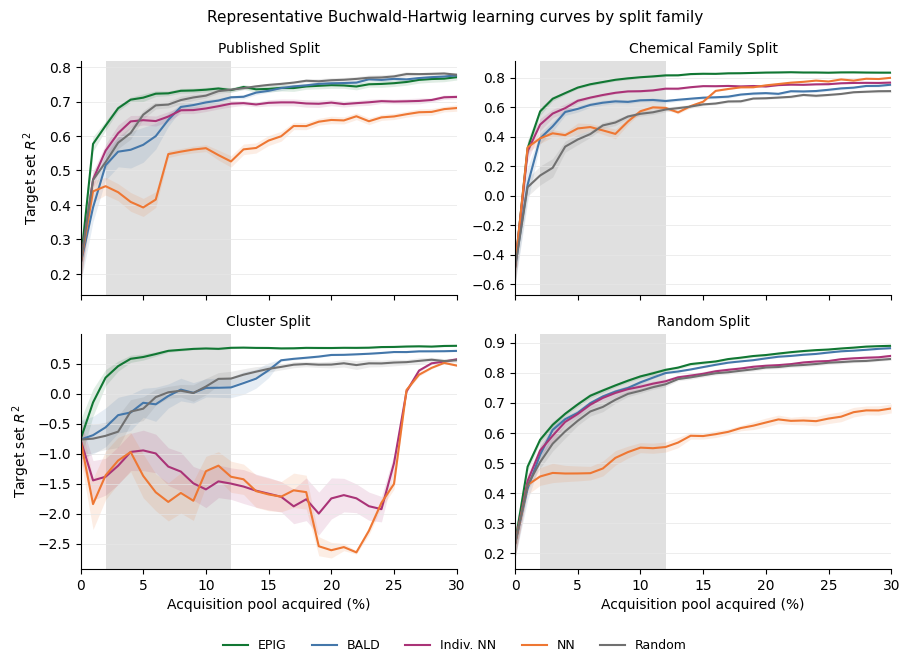

In [5]:
mean_curves = cio.load_mean_curves()
si_curves = pd.read_csv(
    REPO / "supporting_information/data/all_benchmark_learning_curves.csv",
    float_precision="round_trip")

# the four representative Buchwald-Hartwig tasks, one per split family, ordered
# by split family exactly as the manuscript figure orders them
FAMILY_ORDER = ["paper_defined", "chemistry_class_or_substrate_holdout",
                "cluster_based", "true_random"]
PANEL_TASKS = ["tr_bh_009", "bh_paper_additive_plate3_extrapolation",
               "bh_cluster_agglomerative_k8_cl4", "bh_aryl_halide_holdout_14"]
figure_source = si_curves[si_curves["split_id"].isin(PANEL_TASKS)].copy()
panels = (figure_source[["split_family", "split_id"]].drop_duplicates()
          .rename(columns={"split_family": "panel"})
          .merge(mean_curves[["split_id", "split_family", "n_repetitions"]]
                 .drop_duplicates("split_id"), on="split_id"))
panels["rank"] = panels["split_family"].map(FAMILY_ORDER.index)
panels = panels.sort_values("rank").reset_index(drop=True)

curves = mean_curves.assign(
    AF=mean_curves["acq"].map(rr.LABEL),
    pct=(mean_curves["acquisition_fraction"] * 100).round(6))
curves["AF_display"] = curves["AF"].map(rr.DISPLAY)
check = figure_source.assign(pct=figure_source["acquisition_percent"].round(6))
compared = check.merge(curves, left_on=["split_id", "acquisition_function", "pct"],
                       right_on=["split_id", "AF_display", "pct"])
assert len(compared) == len(check), (len(compared), len(check))

fig, axes = plt.subplots(2, 2, figsize=(9.2, 6.6), sharex=True)
for axis, (_, panel) in zip(axes.ravel(), panels.iterrows()):
    task = curves[curves.split_id == panel.split_id]
    axis.axvspan(2, 12, color="0.88", zorder=0, linewidth=0)
    for acq in rr.LABEL_ORDER:
        series = task[task.AF == acq].sort_values("pct")
        name = rr.DISPLAY[acq]
        axis.fill_between(series.pct, series.mean_r2 - series.sem_r2,
                          series.mean_r2 + series.sem_r2,
                          color=METHOD_COLORS[name], alpha=0.13, linewidth=0)
        axis.plot(series.pct, series.mean_r2, color=METHOD_COLORS[name],
                  linewidth=1.5, label=name)
    axis.set_title(panel.panel, fontsize=10)
    axis.set_xlim(0, 30)
    axis.grid(axis="y", color="0.9", linewidth=0.5)
    axis.spines[["top", "right"]].set_visible(False)

for axis in axes[1]:
    axis.set_xlabel("Acquisition pool acquired (%)")
for axis in axes[:, 0]:
    axis.set_ylabel(r"Target set $R^2$")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=9, frameon=False,
           bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Representative Buchwald-Hartwig learning curves by split family",
             fontsize=11)
fig.tight_layout(rect=(0, 0.045, 1, 1))
plt.show()


## 5. Sensitivity to the acquisition window

The evaluation uses seven acquisition windows, with 2–12% as the primary window.

The tables below show how the highest-mean and statistical-competitiveness counts vary with the choice of window.

In [6]:
frames = [cls_primary]
for window_col in [w[0] for w in rr.WINDOWS]:
    if window_col != rr.PRIMARY:
        cls_w, mismatches_w = rr.run_window(per_seed, window_col, nesting)
        assert not mismatches_w, mismatches_w
        frames.append(cls_w)
all_cls = pd.concat(frames, ignore_index=True)
all_counts = rr.counts_from(all_cls)

for value, title in (("highest_mean", "HIGHEST MEAN AUC"),
                     ("competitive", "STATISTICALLY COMPETITIVE")):
    table = (all_counts.pivot_table(index="AF", columns="window", values=value,
                                    aggfunc="first")
             .reindex(index=rr.LABEL_ORDER, columns=WINDOW_ORDER)
             .rename(index=rr.DISPLAY))
    print(f"=== {title} (n/{n_tasks}) ===")
    print(table.to_string(), "\n")

=== HIGHEST MEAN AUC (n/118) ===
window     0-10  2-12  5-15  5-20  5-30  10-20  10-30
AF                                                   
EPIG         67    74    69    65    69     64     67
BALD         22    22    26    31    29     30     31
Indiv. NN    16    12    12    10     8     11     10
NN            9     7     7     7     7      7      6
Random        4     3     4     5     5      6      4 

=== STATISTICALLY COMPETITIVE (n/118) ===
window     0-10  2-12  5-15  5-20  5-30  10-20  10-30
AF                                                   
EPIG        107   105   105   104   102    104    104
BALD         83    79    75    72    72     74     73
Indiv. NN    75    74    67    60    54     60     57
NN           45    40    38    34    32     31     31
Random       65    64    56    56    50     54     46 



## 6. Comparison with released results

The recomputed classifications and counts are compared with the released results and Supporting Information tables. Any disagreement raises an error.

In [7]:
problems: list[str] = []
compared_counts = {
    "per-task result rows": rr.validate_per_task(all_cls, problems)["rows_compared"],
    "SI task-level rows (2-12%)": rr.validate_si_a2_12(all_cls, problems)["rows"],
    "count-table rows": rr.validate_committed_counts_table(all_counts, problems),
    "SI overall count cells": rr.validate_si_counts(all_counts, problems),
    "SI scoped count cells": rr.validate_scoped_counts(all_cls, problems),
    "main results table cells": rr.validate_main_table(all_counts, problems),
}
assert not problems, problems
print("Released results match the recomputed classifications and counts.")

Released results match the recomputed classifications and counts.


## 7. Native integer-step experimental efficiency

For each task, the target is 80% of the improvement from the shared initial mean target-set R² to the highest method-level mean observed at an integer acquisition step within the 30% budget. The endpoint is the first integer step whose method-level mean reaches that target, without interpolation, smoothing, or monotonicity enforcement.


In [8]:
import efficiency_endpoint as efficiency

native_curves, pools = efficiency.load_inputs()
endpoint = efficiency.task_efficiency(native_curves, pools)
primary = pd.read_csv(REPO / "results/efficiency/savings_intervals_100k_primary.csv")

means = endpoint.groupby("AF")["n_reactions"].mean().reindex(efficiency.LABEL_ORDER)
attained = endpoint.groupby("AF")["attained"].sum().reindex(efficiency.LABEL_ORDER)
headline = pd.DataFrame({"mean acquisitions": means, "tasks attaining target": attained})
display(headline.round({"mean acquisitions": 1}))
display(primary[primary["method"].eq("EPIG")][["metric", "mean", "ci_lo", "ci_hi"]])

assert len(endpoint) == 590 and endpoint["split_id"].nunique() == 118
assert abs(means["EPIG"] - 203.6271186440678) < 1e-12
assert attained.to_dict() == {"EPIG": 102, "BALD": 96, "IndvNN": 80, "NN": 45, "Random": 68}


,mean acquisitions,tasks attaining target
AF,,
EPIG,203.6,102
BALD,258.6,96
IndvNN,257.0,80
NN,365.5,45
Random,284.8,68


,metric,mean,ci_lo,ci_hi
0,n_reactions,81.161017,45.629514,120.787893
5,pct_pool,6.896651,4.082596,9.899681


## 8. Additional analyses

The endpoint and savings tables can also be regenerated with the separate scripts:

```bash
python scripts/efficiency_endpoint.py
python scripts/efficiency_pool_spared.py
python scripts/efficiency_reactions_saved.py
python scripts/efficiency_savings_intervals.py
```

The included figure panels can be regenerated with `python scripts/make_figures.py`.

For an example of applying EPIG to a reaction dataset, see `notebooks/using_epig.ipynb`.